In [1]:
from data.dataset import *
from data.image_generator import *
from data.mgf_parser import *
from data.spectrum_parser import *
from models.vit_model import *
import warnings
warnings.filterwarnings("ignore")

In [2]:
folder_path = r"E:\UViT\data\raw\JPST003607_all\mzml"


all_files = sorted([f for f in os.listdir(folder_path) if f.lower().endswith(".mzml")])

grouped_files = []
for i in range(0, len(all_files), 3):
    group = all_files[i:i+3]
    if len(group) == 3: 
        grouped_files.append(group)
    else:
        print(f"⚠️ Last remaining {len(group)} files, not enough for a group, skipping: {group}")



In [3]:
def rep(clipms, result):
    unique_panda = set(clipms.unique())
    unique_result = set(result.unique())
    common = unique_panda.intersection(unique_result)
    ratio = len(common) / len(unique_panda)
    return ratio

In [4]:
import os
import pandas as pd


all_main_results = []


for group_idx, file_group in enumerate(grouped_files):

    print(f"\n{'='*80}")
    print(
        f"Starting processing group {group_idx+1}/{len(grouped_files)}"
    )
    print(
        f"Original mzML file list: {file_group}"
    )
    print(f"{'='*80}")



    file_paths = []
    data_basenames = []

    for file in file_group:
        data_basename = (
            file.replace('.mzML', '')
                .replace('.mzml', '')
        )

        # 对应的 msalign 文件
        file_path = os.path.join(
            folder_path,
            f'{data_basename}_ms2.msalign'
        )

        file_paths.append(file_path)
        data_basenames.append(data_basename)


    spectra_dfs = []
    mono_arr = []


    for i, file_path in enumerate(file_paths):

        file_name = os.path.basename(file_path)

        print(
            f"Processing file "
            f"{i+1}/{len(file_paths)}: "
            f"{file_name}"
        )

        with open(file_path, 'r') as f:

            file_mono_arr, file_spectra_dfs = (
                extract_ms_info_from_mgf(f)
            )

        spectra_dfs.extend(file_spectra_dfs)
        mono_arr.extend(file_mono_arr)

        print(
            f"  ✓ Added "
            f"{len(file_spectra_dfs)} spectra"
        )


    result, updated_dfs = find_intersection(
        spectra_dfs
    )


    all_sub_results = []


    for idx, data_basename in enumerate(
        data_basenames
    ):

        print(
            f"\nProcessing sub-dataset "
            f"{idx+1}/{len(data_basenames)}: "
            f"{data_basename}"
        )

        try:

            clipsms = pd.read_csv(
                f'E:/UViT/Trash/clipsms/JPST003607/'
                f'{data_basename}_ms2/'
                f'Matched_Fragments_Final.csv'
            )

            pandauv = pd.read_csv(
                f'E:/UViT/Trash/pandauv/JPST003607/'
                f'{data_basename}_ms2/'
                f'fragment_matching_result.csv'
            )

            UViT = pd.read_csv(
                f'E:/UViT/Trash/deepuv/JPST003607/'
                f'{data_basename}.csv'
            )

        except FileNotFoundError as e:

            print(
                f"  ⚠️ File does not exist: {e}"
            )

            continue


        protein_len = pandauv['End AA'].max()

        internal_mask = (
            (pandauv['Start AA'] > 1) |
            (pandauv['End AA'] < protein_len)
        )

        pandauv = pandauv[
            (
                internal_mask &
                (pandauv['adjust_PCC'] > 0.8)
            )
            |
            (
                (~internal_mask) &
                (pandauv['adjust_PCC'] > 0.6)
            )
        ].copy()

        if idx == 0:

            clipsms_matches = rep(
                clipsms['Observed Mass'],
                result['mass_source_0']
            )

            mz_col = 'mz'

        else:

            clipsms_matches = rep(
                clipsms['Observed Mass'],
                result[f'mass_{idx}']
            )

            mz_col = f'mz_{idx}'


        pandauv_matches = rep(
            pandauv['mz'],
            result[mz_col]
        )

        UViT_precision = (
            (
                (UViT['pred_label'] == 1) &
                (updated_dfs[idx]['label'] == 1)
            ).sum()
            /
            (UViT['pred_label'] == 1).sum()
        )


        result_dict = {

            'group_id':
                group_idx + 1,

            'file_index':
                idx + 1,

            'data_basename':
                data_basename,

            'file_name':
                file_group[idx],

            'clipsms_matches':
                clipsms_matches,

            'pandauv_matches':
                pandauv_matches,

            'UViT_precision':
                UViT_precision
        }


        all_sub_results.append(
            result_dict
        )

        print(
            f"  clipsms Precision: "
            f"{clipsms_matches}"
        )
        
        print(
            f"  pandauv Precision: "
            f"{pandauv_matches}"
        )
        
        print(
            f"  Pi-UVMorphe Precision: "
            f"{UViT_precision:.4f}"
        )

    # ========================================================
    # 当前组加入总结果
    # ========================================================

    all_main_results.extend(
        all_sub_results
    )


# ============================================================
# 最终汇总
# ============================================================

print(f"\n{'='*80}")
print("Final Precision Summary")
print(f"{'='*80}")


final_summary_df = pd.DataFrame(
    all_main_results
)




Starting processing group 1/36
Original mzML file list: ['ADC_FcUVPD0,5mJ1pPostUVPDfractionationPTCRLowerWindow6Scans_1.mzML', 'ADC_FcUVPD0,5mJ1pPostUVPDfractionationPTCRLowerWindow6Scans_2.mzML', 'ADC_FcUVPD0,5mJ1pPostUVPDfractionationPTCRLowerWindow6Scans_3.mzML']
Processing file 1/3: ADC_FcUVPD0,5mJ1pPostUVPDfractionationPTCRLowerWindow6Scans_1_ms2.msalign
  ✓ Added 1 spectra
Processing file 2/3: ADC_FcUVPD0,5mJ1pPostUVPDfractionationPTCRLowerWindow6Scans_2_ms2.msalign
  ✓ Added 1 spectra
Processing file 3/3: ADC_FcUVPD0,5mJ1pPostUVPDfractionationPTCRLowerWindow6Scans_3_ms2.msalign
  ✓ Added 1 spectra

Processing sub-dataset 1/3: ADC_FcUVPD0,5mJ1pPostUVPDfractionationPTCRLowerWindow6Scans_1
  clipsms Precision: 0.4244712990936556
  pandauv Precision: 0.6395939086294417
  Pi-UVMorphe Precision: 0.7656

Processing sub-dataset 2/3: ADC_FcUVPD0,5mJ1pPostUVPDfractionationPTCRLowerWindow6Scans_2
  clipsms Precision: 0.3217893217893218
  pandauv Precision: 0.5368171021377672
  Pi-UVMorphe


Pairwise paired t-test p-values:

ClipsMS vs PandaUV: p = 3.8380e-56
ClipsMS vs Pi-UVMorphe: p = 4.6925e-63
PandaUV vs Pi-UVMorphe: p = 1.4733e-29


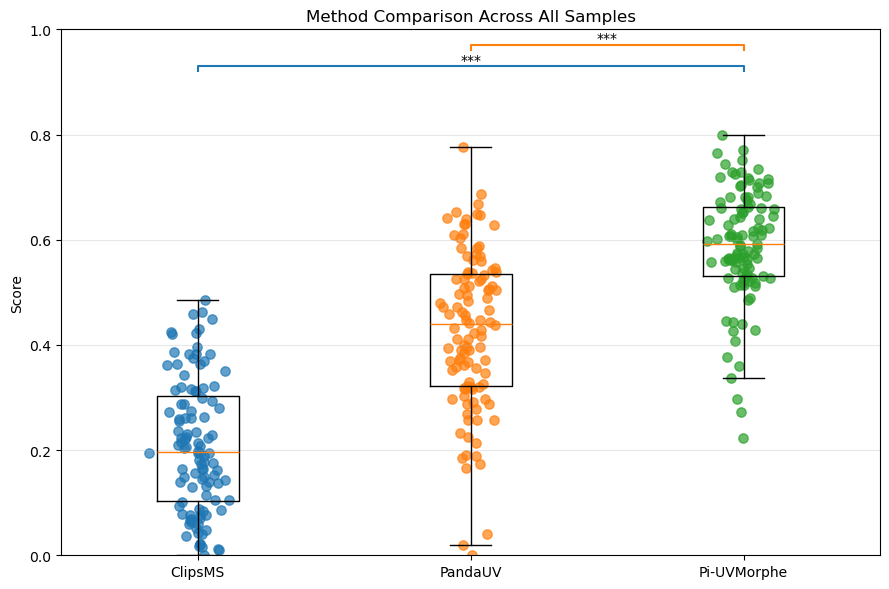

In [5]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import ttest_rel
from itertools import combinations

plot_df = final_summary_df[[
    'clipsms_matches',
    'pandauv_matches',
    'UViT_precision'
]].copy()

plot_df.columns = [
    'ClipsMS',
    'PandaUV',
    'Pi-UVMorphe'
]

methods = plot_df.columns.tolist()

data = [plot_df[col].dropna().values for col in methods]

print("\nPairwise paired t-test p-values:\n")

p_values = {}

for a, b in combinations(methods, 2):

    x = plot_df[a]
    y = plot_df[b]

    valid = ~(x.isna() | y.isna())

    stat, p = ttest_rel(
        x[valid],
        y[valid]
    )

    p_values[(a, b)] = p

    print(f"{a} vs {b}: p = {p:.4e}")


plt.figure(figsize=(9,6))

plt.boxplot(
    data,
    labels=methods,
    showfliers=False
)

for i, y in enumerate(data, start=1):

    x = np.random.normal(i, 0.05, size=len(y))

    plt.scatter(
        x,
        y,
        alpha=0.7,
        s=45
    )

plt.ylabel('Score')

plt.title('Method Comparison Across All Samples')

plt.ylim(0, 1)

plt.grid(axis='y', alpha=0.3)


uvit_idx = methods.index('Pi-UVMorphe') + 1

height = 0.92
step = 0.04

for method in methods:

    if method == 'Pi-UVMorphe':
        continue

    other_idx = methods.index(method) + 1

    if ('Pi-UVMorphe', method) in p_values:
        p = p_values[('Pi-UVMorphe', method)]
    else:
        p = p_values[(method, 'Pi-UVMorphe')]

    if p < 0.001:
        stars = '***'
    elif p < 0.01:
        stars = '**'
    elif p < 0.05:
        stars = '*'
    else:
        stars = 'ns'

    plt.plot(
        [uvit_idx, uvit_idx, other_idx, other_idx],
        [height, height+0.01, height+0.01, height],
        lw=1.5
    )

    plt.text(
        (uvit_idx + other_idx)/2,
        height+0.015,
        stars,
        ha='center'
    )

    height += step

plt.tight_layout()

plt.show()